<h1>CME538 - Introduction to Data Science</h1>
<h2>Lecture 3.3 - Cleaning data</h2>
<p>Why this notebook? You will test cleaning decisions against travel-expense records. Separate unknown values, unusual claims, and confirmed errors before calculating a cost summary.</p>
<p>Central question: Which problems warrant correction, review, or limits on the analysis?</p>
<p>You will check date parsing, repeated records, missing values, and plausibility rules. You will standardize labels and units, then investigate unusual totals. Preserve the source and record the reason for each change.</p>
<h3>Lecture Structure</h3>
<ol>
<li><a href="#section1">Type Conversion</a></li>
<li><a href="#section2">Duplicates</a></li>
<li><a href="#section3">Missing Data</a></li>
<li><a href="#section4">Implausible Data</a></li>
<li><a href="#section5">Character Encoding</a></li>
<li><a href="#section6">Representation and Relevance</a></li>
<li><a href="#section7">Outliers</a></li>
</ol>
<p>Worked examples: <a href="#missing-evidence">missing evidence in travel claims</a>, <a href="#wine-vintage-check">wine-vintage strings</a>, and <a href="#repeatable-cleaning-rule">a repeatable cleaning rule</a>. These illustrative datasets stay separate from the recorded travel disclosures.</p>
<p>File example: <a href="#character-encoding">detect a CSV encoding with chardet and write a UTF-8 copy</a>.</p>
<h3>Lecture slides and data sources</h3>
<p><a href="../slides/week3_lecture3.pptx">Lecture slides</a>, <a href="https://open.canada.ca/data/en/dataset/009f9a49-c2d9-4d29-a6d4-1a228da335ce/resource/8282db2a-878f-475c-af10-ad56aa8fa72c">Government of Canada travel disclosures and data dictionary</a>, and <a href="https://open.canada.ca/en/open-government-licence-canada">Open Government Licence - Canada</a>.</p>
<p>This lesson uses a fixed local snapshot, not the portal's live records.</p>

<h2>Setup Notebook</h2>
<p><code>travelq.csv</code> combines federal travel-expense disclosures. Each row represents one submitted claim. Monetary fields use Canadian dollars. The extract contains ordinary claims through 2024 and anomalies for review.</p>
<p>Preserve <code>raw</code> and edit only <code>claims</code>. <a href="utils.py">utils.py</a> holds display settings and reusable helpers. The notebook shows the cleaning decisions.</p>
<p>The character-encoding example uses <a href="https://chardet.readthedocs.io/en/latest/usage.html">chardet</a>, a library for estimating the encoding of file bytes. Run the setup cell below before class. The examples use local files.</p>

In [1]:
%pip install --quiet chardet

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Third-party libraries
import chardet
import numpy as np
import pandas as pd

# Local teaching helpers
from utils import (configure_notebook, audit_vintage_years, plot_wine_ages,
                   preview_flagged_claims, plot_claim_totals)

configure_notebook()

<p>Load the file and preserve an untouched copy. Edit a working copy for comparison with the source.</p>

In [3]:
raw = pd.read_csv('travelq.csv', low_memory=False)
claims = raw.copy()
claims[['ref_number', 'start_date', 'end_date', 'total']].head(3)

,ref_number,start_date,end_date,total
0,T-20120-P11-001,2020-02-03,2020-02-04,1118.46
1,T-2020-P11-0001,2020-02-09,2020-02-13,2597.14
2,T-2020-P11-0002,2020-02-09,2020-02-14,4128.74


<a id='section1'></a>
<h2>1. Type Conversion</h2>
<p>Question: Which storage types conflict with the variables' meanings?</p>
<p>You need dates before calculating trip lengths. Inspect the types, parse the documented format, and calculate elapsed days. Count parse failures before trusting the result.</p>

In [4]:
claims.info()

<class 'pandas.DataFrame'>
RangeIndex: 123714 entries, 0 to 123713
Data columns (total 21 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ref_number              123712 non-null  str    
 1   disclosure_group        99899 non-null   str    
 2   title_en                110717 non-null  str    
 3   title_fr                122954 non-null  str    
 4   name                    123142 non-null  str    
 5   purpose_en              111347 non-null  str    
 6   purpose_fr              123612 non-null  str    
 7   start_date              123714 non-null  str    
 8   end_date                122871 non-null  str    
 9   destination_en          111032 non-null  str    
 10  destination_fr          123019 non-null  str    
 11  airfare                 82910 non-null   float64
 12  other_transport         120198 non-null  float64
 13  lodging                 94217 non-null   float64
 14  meals                   99259 n

<p>The source schema uses ISO dates, <code>YYYY-MM-DD</code>. With <code>errors='coerce'</code>, pandas converts an invalid date string to <code>NaT</code> instead of stopping. Check for failures after parsing.</p>

In [5]:
claims['start_date'] = pd.to_datetime(
    claims['start_date'], format='%Y-%m-%d', errors='coerce'
)
claims['end_date'] = pd.to_datetime(
    claims['end_date'], format='%Y-%m-%d', errors='coerce'
)

<p>A parse failure starts with a recorded value and ends with <code>NaT</code>. Compare the parsed dates with <code>raw</code> so existing gaps do not count as failures. Summing each Boolean column counts the failures.</p>

In [6]:
date_columns = ['start_date', 'end_date']
parse_failures = raw[date_columns].notna() & claims[date_columns].isna()
parse_failures.sum()

start_date    0
end_date      0
dtype: int64

<p><code>trip_days</code> measures elapsed calendar days. A same-day trip has a duration of 0. Keep negative durations for the plausibility check.</p>

In [7]:
claims['trip_days'] = (
    claims['end_date'] - claims['start_date']
).dt.days
claims[['start_date', 'end_date', 'trip_days']].head()

,start_date,end_date,trip_days
0,2020-02-03,2020-02-04,1.0
1,2020-02-09,2020-02-13,4.0
2,2020-02-09,2020-02-14,5.0
3,2020-02-09,2020-02-12,3.0
4,2020-02-09,2020-02-12,3.0


<p>Takeaway: Pair <code>errors='coerce'</code> with a failure audit. Specify the expected format and preserve the source. Inspect missing results and suspicious derived values.</p>
<p>Back to the slides: When do two records represent the same event?</p>

<a id='section2'></a>
<h2>2. Duplicates</h2>
<p>Question: Which rows repeat a claim, and which share an identifier?</p>
<p>Counting a claim twice would inflate a cost summary. A repeated identifier alone does not prove a repeated claim. Compare exact row matches with repeated <code>ref_number</code> values across institutions. Inspect the evidence before removing rows.</p>

In [8]:
print('Exact repeated rows:', raw.duplicated().sum())
print('Repeated reference numbers:', raw.duplicated('ref_number').sum())
print('Unique reference numbers:', raw['ref_number'].nunique())

Exact repeated rows: 3896
Repeated reference numbers: 49448
Unique reference numbers: 74265


<p>Inspect exact matches in the source. Treat identical rows as suspected duplicates. Separate submissions sometimes share all visible fields. Institutions also use overlapping reference-number schemes.</p>
<p>Confirm event identity with a submission-level ID or documentation of the extract's construction.</p>

In [9]:
duplicate_rows = raw.loc[raw.duplicated(keep=False)].sort_values('ref_number')
duplicate_rows[['ref_number', 'owner_org', 'start_date', 'end_date', 'total']].head(4)

,ref_number,owner_org,start_date,end_date,total
123396,0100644490297925,dnd-mdn,2019-02-02,2019-02-03,892.53
86026,0100644490297925,dnd-mdn,2019-02-02,2019-02-03,892.53
119315,045882,cmhc-schl,2023-05-24,2023-05-26,415.18
10144,045882,cmhc-schl,2023-05-24,2023-05-26,415.18


<p>This extract lacks enough provenance to confirm whether identical rows represent one submission. Flag every member of each identical-row group and retain the rows in the analysis copy. Remove an extra copy only after a submission ID or source review confirms duplicate ingestion.</p>

In [10]:
claims['suspected_exact_duplicate'] = raw.duplicated(keep=False)
claims['suspected_exact_duplicate'].value_counts()

suspected_exact_duplicate
False    115922
True       7792
Name: count, dtype: int64

<p>Takeaway: Define record identity before removing duplicates. An identical row needs source review. Use a field as a key only after checking its documented scope and meaning.</p>
<p>Back to the slides: What do empty cells and absent rows mean?</p>

<a id='section3'></a>
<h2>3. Missing Data</h2>
<p>Question: Does a missing expense mean zero, unknown, inapplicable, or unreported?</p>
<p>Distinguish an empty cell from an absent field or trip. Then test whether replacing missing expense components with zero reproduces the reported totals. Use the result to assess the proposed cleaning rule.</p>

<a id='mfml-missing-evidence'></a>
<a id='missing-evidence'></a>
<h3>Question: What evidence is missing?</h3>
<p>You want trip costs and evidence of trip outcomes. Compare these illustrative claims with a separate trip register. The example does not alter the real disclosure data.</p>
<ol>
<li>Trip B has an empty lodging amount.</li>
<li>The claims table contains no outcome field.</li>
<li>The trip register lists trip D, but the claims extract has no corresponding row.</li>
</ol>
<p>Which gaps does <code>isna()</code> detect? Which other checks and sources do you need?</p>
<p>An empty amount does not establish zero cost. An absent claim does not establish an absent trip.</p>

In [11]:
evidence_demo = pd.DataFrame({
    'trip_id': ['A', 'B', 'C'],
    'purpose': ['Conference', 'Regional meeting', 'Site visit'],
    'lodging_cad': [300, np.nan, 150],
})
trip_register_demo = pd.Series(['A', 'B', 'C', 'D'], name='trip_id')
evidence_demo

,trip_id,purpose,lodging_cad
0,A,Conference,300.0
1,B,Regional meeting,NaN
2,C,Site visit,150.0


<p>Count missing cells in each column with <code>isna().sum()</code>.</p>

In [12]:
evidence_demo.isna().sum()

trip_id        0
purpose        0
lodging_cad    1
dtype: int64

<p>Check whether the table includes an outcome column.</p>

In [13]:
'outcome' in evidence_demo.columns

False

<p>The separate trip register lists four trips.</p>

In [14]:
trip_register_demo

0    A
1    B
2    C
3    D
Name: trip_id, dtype: str

<p><code>isin()</code> checks which register IDs appear in the claims table. The <code>~</code> operator reverses the selection to show absent trips.</p>

In [15]:
trip_register_demo[~trip_register_demo.isin(evidence_demo['trip_id'])]

3    D
Name: trip_id, dtype: str

<p><code>isna()</code> checks cells within existing rows and columns. A schema check identifies an absent field but supplies no missing values. A coverage check needs an independent population definition or list. Without the trip register, this table would not identify trip D.</p>
<p>Ask what B's empty amount means. Obtain trip-outcome evidence. Check whether the extract's scope includes D. Filling one cell would resolve none of these evidence gaps.</p>
<p>Return to the disclosure data. Audit the recorded cells, but do not treat this extract as a complete list of all trips or people.</p>

<p>Step 1: Count missing cells with <code>isna().sum()</code>. Show the twelve columns with the most gaps.</p>

In [16]:
missing_counts = claims.isna().sum().sort_values(ascending=False)
missing_counts.head(12)

additional_comments_fr    106329
additional_comments_en    105462
airfare                    40804
lodging                    29497
meals                      24455
disclosure_group           23815
title_en                   12997
destination_en             12682
purpose_en                 12367
other_expenses             10805
other_transport             3516
end_date                     843
dtype: int64

<p>Divide by the number of rows to report percentages. The same count represents different shares in small and large tables.</p>

In [17]:
(100 * missing_counts / len(claims)).head(12).round(1)

additional_comments_fr    85.9
additional_comments_en    85.2
airfare                   33.0
lodging                   23.8
meals                     19.8
disclosure_group          19.3
title_en                  10.5
destination_en            10.3
purpose_en                10.0
other_expenses             8.7
other_transport            2.8
end_date                   0.7
dtype: float64

<p>Step 2: Read the source requirements. The Government of Canada schema requires <code>total</code> and treats component expenses and comments as optional. An optional field does not distinguish zero from unavailable or unreported values. Check documentation and compare components with reported totals.</p>

<p>Step 3: Normalize explicit missing markers. CSV fields contain empty values or strings such as <code>None</code>, <code>-</code>, and <code>--</code>. Use <code>isin()</code> to count cells matching these exact strings. Convert only documented or inspected markers to <code>pd.NA</code>. Do not replace substrings within place names.</p>

In [18]:
marker_columns = [
    'destination_en', 'destination_fr',
    'additional_comments_en', 'additional_comments_fr',
]
missing_tokens = ['None', '-', '--']

for column in marker_columns:
    claims[column] = claims[column].astype('string').str.strip()

claims[marker_columns].isin(missing_tokens).sum()

destination_en            25
destination_fr             9
additional_comments_en    27
additional_comments_fr    22
dtype: int64

<p><code>replace()</code> converts these marker strings to missing values.</p>

In [19]:
claims[marker_columns] = claims[marker_columns].replace(missing_tokens, pd.NA)

<p>Step 4: Select records and fields for the task. This lesson analyses costs in English. The two comment fields fall outside this task. A row without the required <code>total</code> contributes no known claim amount. Exclude these fields and rows from the working view. Preserve the source in <code>raw</code>.</p>

In [20]:
claims = claims.drop(columns=['additional_comments_en', 'additional_comments_fr'])
claims = claims.dropna(subset=['total'])
claims.shape

(123518, 21)

<p>Step 5: Test the zero-fill rule. If each missing component meant zero, summing known components would reproduce the reported total to the cent. Test this implication on rows with missing components. Keep the data unchanged during the test.</p>

In [21]:
component_columns = [
    'airfare', 'other_transport', 'lodging', 'meals', 'other_expenses'
]
has_missing_component = claims[component_columns].isna().any(axis=1)
zero_filled_sum = claims.loc[has_missing_component, component_columns].fillna(0).sum(axis=1)
agrees_with_total = np.isclose(
    zero_filled_sum,
    claims.loc[has_missing_component, 'total'],
    atol=0.01,
    rtol=0,
)

print('Claims with a missing component:', has_missing_component.sum())
print('Sums matching the total:', agrees_with_total.sum())
print('Percent matching:', round(100 * agrees_with_total.mean(), 1))

Claims with a missing component: 75022
Sums matching the total: 21975
Percent matching: 29.3


<p>Takeaway: The schema permits missing components. For most affected rows, zero-filling does not reproduce the reported total. Retain the component gaps and use <code>total</code> when the analysis needs a complete claim amount.</p>
<p>Back to the slides: Does a present, correctly typed value always make sense?</p>

<a id='section4'></a>
<h2>4. Implausible Data</h2>
<p>Question: Which values conflict with documented rules for this dataset?</p>
<p>Calculate the wine ages from the slides. Apply one inventory policy to two deliveries. Then assess travel dates and amounts using separate, source-specific rules. Attach a reason to each review flag. A flag alone does not establish an error.</p>

<a id='mfml-wine-years'></a>
<a id='wine-vintage-check'></a>
<h3>The wine-age calculation</h3>
<p>Successful arithmetic does not validate input meaning. This illustrative inventory contains vintage strings <code>2018</code>, <code>2012</code>, <code>18</code>, and <code>12</code>. Check whether each string specifies a complete year before calculating an age. Use the fixed reference year 2026.</p>
<p>Question: What ages follow from converting each string to an integer and subtracting the result from 2026? Which inputs require an assumption about the century?</p>

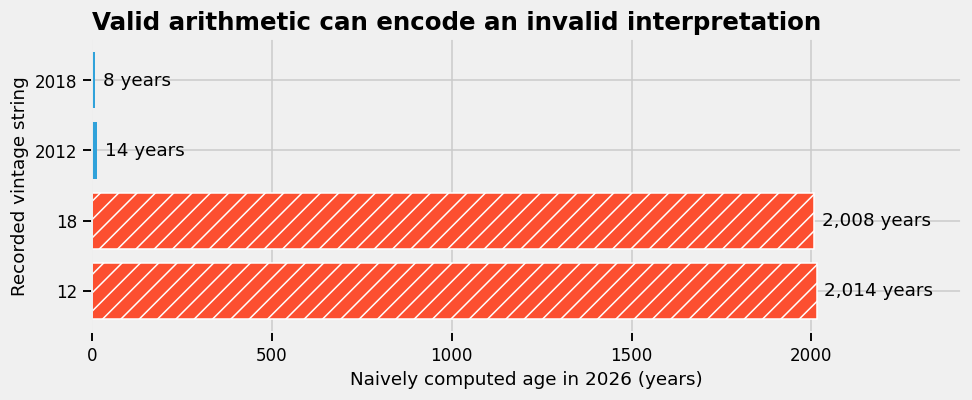

In [22]:
WINE_REFERENCE_YEAR = 2026
wine_raw = pd.Series(['2018', '2012', '18', '12'], name='recorded_year', dtype='string')
wine_naive = wine_raw.to_frame()
wine_naive['naive_age_years'] = WINE_REFERENCE_YEAR - pd.to_numeric(wine_raw)
plot_wine_ages(wine_naive, reference_year=WINE_REFERENCE_YEAR)

<p>Interpreting <code>18</code> as year 18 produces the displayed subtraction result. The input alone supports neither year 18 nor year 2018.</p>
<p>For this fictional retailer, use the following inventory policy.</p>
<ul>
<li>Trim surrounding whitespace and require four digits.</li>
<li>Accept years from 1850 through 2026.</li>
<li>Send ambiguous or invalid strings for review. Preserve the original values.</li>
</ul>
<p>The 1850 limit describes this retailer's inventory scope, not all wine. Calculate ages only for accepted values. Ask the source to clarify two-digit years rather than adding an assumed century.</p>

<a id='mfml-repeatable-rule'></a>
<a id='repeatable-cleaning-rule'></a>
<h3>Apply the same rule to each batch</h3>
<p>Manual edits address individual cells. The function <code>audit_vintage_years</code> in <a href="utils.py">utils.py</a> applies the documented policy to both deliveries. The function returns an audit table without changing the input.</p>
<p>Question: How should the rule classify <code>2020</code>, <code>2027</code>, <code>abcd</code>, and <code>05</code>? Should the new batch receive different rules for two-digit years?</p>
<p>This policy uses fixed criteria, not estimates from the records. Later methods estimate preprocessing parameters from training data. Reuse those fitted parameters without fitting on the test set.</p>

In [23]:
WINE_MIN_YEAR = 1850
wine_audit = audit_vintage_years(
    wine_raw, reference_year=WINE_REFERENCE_YEAR, min_year=WINE_MIN_YEAR
)
wine_audit

,recorded_year,accepted_year,age_years,decision
0,2018,2018,8,accepted
1,2012,2012,14,accepted
2,18,<NA>,<NA>,ambiguous two-digit year
3,12,<NA>,<NA>,ambiguous two-digit year


In [24]:
wine_next_batch = pd.Series(['2020', '2027', 'abcd', '05'], dtype='string')
wine_next_audit = audit_vintage_years(
    wine_next_batch, reference_year=WINE_REFERENCE_YEAR, min_year=WINE_MIN_YEAR
)
wine_next_audit

,recorded_year,accepted_year,age_years,decision
0,2020,2020,6,accepted
1,2027,<NA>,<NA>,future year
2,abcd,<NA>,<NA>,invalid format
3,05,<NA>,<NA>,ambiguous two-digit year


<p>Takeaway: Trace a suspicious result to the input meaning. Document the policy and test the same function on another batch. A review flag does not prove an incorrect record. If the supplier confirms a century convention, update the rule rather than individual examples.</p>
<p>Return to <code>claims</code>. The snapshot covers ordinary records from 2003 through 2024. Check both dates, date order, and all monetary fields. Review negative amounts for corrections or reversals before deciding how to treat them. Missing dates stay unknown. Comparisons involving <code>NaT</code> do not establish valid dates.</p>
<p>Use travel-data rules here. Do not apply the retailer's 1850 limit to travel records.</p>

In [25]:
EXPECTED_DATE_START = pd.Timestamp('2003-01-01')
EXPECTED_DATE_END = pd.Timestamp('2024-12-31')
monetary_columns = component_columns + ['total']
plausibility_flags = pd.DataFrame(index=claims.index)
plausibility_flags['negative monetary value'] = (
    (claims[monetary_columns] < 0).any(axis=1)
)
plausibility_flags['date outside 2003-2024 snapshot'] = (
    (claims['start_date'] < EXPECTED_DATE_START)
    | (claims['start_date'] > EXPECTED_DATE_END)
    | (claims['end_date'] < EXPECTED_DATE_START)
    | (claims['end_date'] > EXPECTED_DATE_END)
)
plausibility_flags['end before start'] = (
    claims['end_date'] < claims['start_date']
)

plausibility_flags.sum()

negative monetary value            338
date outside 2003-2024 snapshot     23
end before start                   233
dtype: int64

<p>Inspect flagged examples and their reasons. A negative component triggers review even with a positive total. Distinguish a reason for review from proof of an error.</p>

In [26]:
flagged_mask = plausibility_flags.any(axis=1)
preview_flagged_claims(claims, plausibility_flags)

,Claim,Trip days,Total (CAD),Review reason
6,T-2020-P11-0006,3.0,1953.50,Negative amount
334,T-2019-P5-0025,-728.0,1510.58,End before start
373,T-2019-P7-0005,-1094.0,1077.12,End before start
685,T-2021-P12-0007,-7304.0,402.93,Date outside snapshot; End before start
880,T-2022-P10-0012,-730.0,10.00,End before start


<p>For this cost-summary exercise, exclude flagged rows from the analysis view and retain them in <code>flagged_claims</code>. In production, a domain owner should decide whether each category warrants correction, retention, or exclusion.</p>

In [27]:
flagged_claims = claims.loc[flagged_mask].copy()
claims = claims.loc[~flagged_mask].copy()
print('Claims set aside for review:', len(flagged_claims))
print('Claims retained for the cost summary:', len(claims))

Claims set aside for review: 586
Claims retained for the cost summary: 122932


<p>Takeaway: Base plausibility rules on source documentation and domain meaning. Check both dates and their order. Retain flagged records for review rather than deleting evidence.</p>
<p>Back to the slides: Which representations and fields suit the analysis?</p>

<a id='section5'></a>
<a id='character-encoding'></a>
<h2>5. Character Encoding</h2>
<p>Question: How do you choose an encoding when reading a text file?</p>
<p>Use chardet to estimate the travel file's encoding. Inspect the decoded text, then save and read a UTF-8 copy. Keep the source unchanged.</p>
<p>An encoding maps text to bytes. Decoding maps those bytes back to text. The accented character in <code>Montréal</code> shows why the choice matters.</p>

In [28]:
place = 'Montréal'
utf8_bytes = place.encode('utf-8')
print('Text:', place)
print('UTF-8 bytes:', utf8_bytes)
print('Decoded text:', utf8_bytes.decode('utf-8'))

Text: Montréal
UTF-8 bytes: b'Montr\xc3\xa9al'
Decoded text: Montréal


<h3>Estimate a file's encoding with chardet</h3>
<p>If <code>pd.read_csv()</code> raises a <code>UnicodeDecodeError</code>, the assumed encoding does not fit the file bytes. First check the source documentation. Without a documented encoding, use <code>chardet.detect()</code> to estimate one.</p>
<p>Open <code>travelq.csv</code> in binary mode with <code>'rb'</code>. Read the first 100,000 bytes as a sample. Binary mode reads bytes without decoding them.</p>

In [29]:
with open('travelq.csv', 'rb') as file:
    file_bytes = file.read(100_000)

file_bytes[:100]

b'ref_number,disclosure_group,title_en,title_fr,name,purpose_en,purpose_fr,start_date,end_date,destina'

<p>Pass the bytes to <code>chardet.detect()</code>. The result includes an encoding name and a confidence score between 0 and 1. Treat the result as an estimate. Check the source and inspect accented text before accepting the choice.</p>

In [30]:
encoding_info = chardet.detect(file_bytes)
print('Encoding:', encoding_info['encoding'])
print('Confidence:', encoding_info['confidence'])

Encoding: utf-8
Confidence: 0.8323076


<p>Pass the encoding name to <code>read_csv()</code>. Load five rows and inspect the French text. This snapshot already uses UTF-8, so no encoding repair is needed.</p>

In [31]:
detected_encoding = encoding_info['encoding']
encoding_preview = pd.read_csv(
    'travelq.csv', encoding=detected_encoding, nrows=5
)
encoding_preview[['name', 'title_fr']]

,name,title_fr
0,Philip Rizcallah,Président directeur-général
1,"Bérubé, Paul-Claude",Président
2,"Reid, Mary",vice-présidente
3,"McLaughlin, Joseph",Membre du conseil de direction
4,"Haan, Maureen",Membre du conseil de direction


<p>Write these five rows to a separate file with an explicit output encoding. <code>index=False</code> prevents pandas from adding its row index as a CSV column. Keep the original file unchanged.</p>

In [32]:
encoding_preview.to_csv(
    'travelq_utf8_preview.csv', encoding='utf-8', index=False
)

<p>Read the saved copy as UTF-8. Check whether the accented names and titles survived the write and read.</p>

In [33]:
utf8_preview = pd.read_csv('travelq_utf8_preview.csv', encoding='utf-8')
utf8_preview[['name', 'title_fr']]

,name,title_fr
0,Philip Rizcallah,Président directeur-général
1,"Bérubé, Paul-Claude",Président
2,"Reid, Mary",vice-présidente
3,"McLaughlin, Joseph",Membre du conseil de direction
4,"Haan, Maureen",Membre du conseil de direction


<p>Takeaway: Read source bytes with the source encoding. Use chardet as an estimate when documentation is absent. Check the decoded text and choose the output encoding explicitly.</p>
<p>Back to the slides: Continue with Inconsistent Data Entry and Unit Conversion.</p>

<a id='section6'></a>
<a id='representation-and-relevance'></a>
<h2>6. Representation and Relevance</h2>
<p>Question: Which spellings represent the same value? Which fields belong in this analysis?</p>
<p>Normalize destination labels and express two temperatures in the same units. Select the fields needed for this English-language cost analysis. Preserve the original records.</p>

In [34]:
destination_before = claims['destination_en'].nunique(dropna=True)
claims['destination_key'] = (
    claims['destination_en'].astype('string').str.strip().str.casefold()
)
destination_after = claims['destination_key'].nunique(dropna=True)

toronto_variants = (
    claims.loc[
        claims['destination_en'].str.contains('toronto', case=False, na=False),
        'destination_en',
    ]
    .value_counts()
    .head(10)
)
print('unique destination labels before:', destination_before)
print('unique conservative keys after:  ', destination_after)
toronto_variants

unique destination labels before: 20437
unique conservative keys after:   18250


destination_en
Toronto, Ontario, Canada    6018
Toronto, ON                 3533
Toronto, Ontario            2233
Toronto                     1522
toronto, ontario, canada     689
toronto, on                  423
toronto, ontario             240
toronto                      189
Toronto (Ontario) Canada     170
Toronto, (Ontario)           118
Name: count, dtype: Int64

<p>Case and whitespace normalization do not establish geographic equivalence. Treat <code>Toronto, ON</code> and <code>Toronto, Ontario</code> as equivalent only under a documented geography rule. Convert units before comparing measurements.</p>

<p>These two readings describe the same temperature. Copy the recorded values, then convert only the Fahrenheit reading to Celsius.</p>

In [35]:
temperature = pd.DataFrame({
    'recorded value': [20.0, 68.0],
    'recorded unit': ['C', 'F'],
})
temperature['temperature_c'] = temperature['recorded value']
fahrenheit = temperature['recorded unit'] == 'F'
temperature.loc[fahrenheit, 'temperature_c'] = (
    temperature.loc[fahrenheit, 'recorded value'] - 32
) * 5 / 9
temperature

,recorded value,recorded unit,temperature_c
0,20.0,C,20.0
1,68.0,F,20.0


<p>The source contains English and French columns. This task uses English display fields. Exclude the French display columns from the working view. Their exclusion reflects task scope, not a data defect. The original fields stay in <code>raw</code>.</p>

In [36]:
french_columns = [column for column in claims if column.endswith('_fr')]
claims = claims.drop(columns=french_columns)
print('French columns removed from working view:', len(french_columns))
print('Columns now:', claims.shape[1])

French columns removed from working view:

 3
Columns now: 19


<p>Takeaway: Preserve source values during normalization. Define explicit rules for abbreviations and unit conversion. Select relevant fields from the analysis question.</p>
<p>Back to the slides: Does an unusual claim imply an incorrect record?</p>

<a id='section7'></a>
<a id='outliers'></a>
<h2>7. Outliers</h2>
<p>Question: Which totals warrant review? What evidence should guide your next action?</p>
<p>Compare the full distribution with a restricted viewing range. Calculate 1.5 × IQR flags and inspect the largest claims. Both panels show the same records. Only the horizontal axis range changes. A high expense alone does not prove an error.</p>

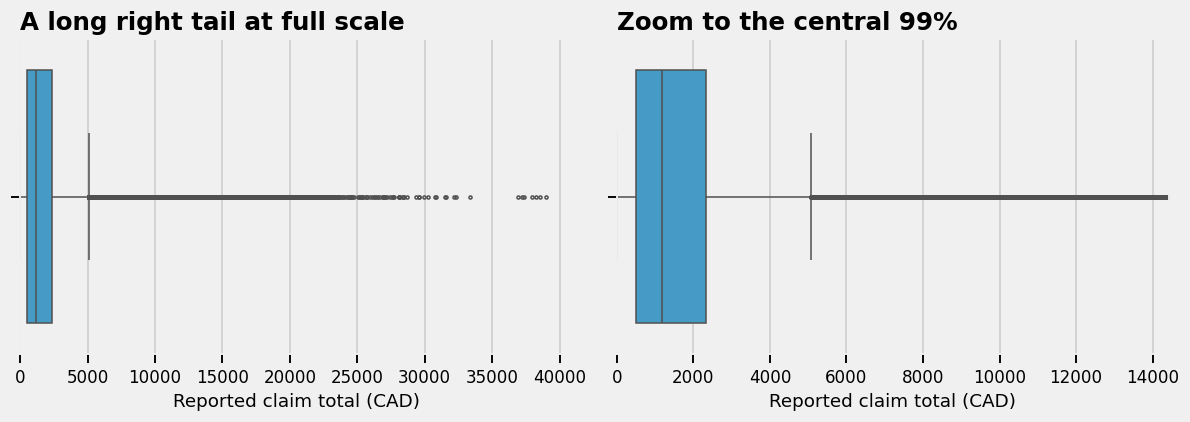

In [37]:
plot_claim_totals(claims['total'])

<p>The 1.5 × IQR rule flags values outside <code>[Q1 - 1.5 × IQR, Q3 + 1.5 × IQR]</code>. This statistical rule does not establish whether a trip or expense is legitimate.</p>

In [38]:
q1 = claims['total'].quantile(0.25)
q3 = claims['total'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
claims['total_iqr_flag'] = (claims['total'] < lower_fence) | (claims['total'] > upper_fence)

print(f'Q1 = ${q1:,.2f}; Q3 = ${q3:,.2f}; IQR = ${iqr:,.2f}')
print(f'flag totals below ${lower_fence:,.2f} or above ${upper_fence:,.2f}')
print('claims flagged:', claims['total_iqr_flag'].sum())

Q1 = $499.42; Q3 = $2,333.02; IQR = $1,833.61
flag totals below $-2,250.99 or above $5,083.43
claims flagged: 11199


<p>Do not delete a value to produce a smoother distribution. Match your response to the evidence.</p>
<ul>
<li>Documented recording or unit error: correct the value using source evidence.</li>
<li>Unresolved reliability problem: retain the record separately and report the exclusion rule.</li>
<li>Legitimate rare event: retain the value and assess a robust summary or transformation.</li>
</ul>

In [39]:
largest_claims = claims.nlargest(5, 'total').copy()
largest_claims['known component sum'] = largest_claims[component_columns].sum(
    axis=1, min_count=1
)
largest_claims['missing components'] = largest_claims[component_columns].isna().sum(axis=1)
largest_claims[[
    'ref_number', 'trip_days', 'total', 'known component sum', 'missing components',
]]

,ref_number,trip_days,total,known component sum,missing components
71783,T-2023-P04-00032,6.0,38983.15,38983.15,0
24536,T-2024-P3-00025,2.0,38516.95,38516.95,0
71349,T-2022-P12-00034,6.0,38248.20,1030.21,1
62616,T-2010-P04-00046,10.0,37957.87,37957.87,0
70237,T-2021-P01-00007,46.0,37327.94,20201.66,1


<p>The working view retains the largest claims. Known components match the total for some claims. Missing components prevent reconciliation for others. Neither result alone establishes a legitimate trip or expense. Review the source records.</p>
<p>Use <code>info()</code> to review the working table's row count, missing values, and converted types. The reasons for changes appear beside each cleaning step. Original records stay in <code>raw</code>, and claims excluded by the plausibility rules stay in <code>flagged_claims</code>.</p>

In [40]:
claims.info()

<class 'pandas.DataFrame'>
Index: 122932 entries, 0 to 123713
Data columns (total 20 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   ref_number                 122930 non-null  str           
 1   disclosure_group           99341 non-null   str           
 2   title_en                   110014 non-null  str           
 3   name                       122360 non-null  str           
 4   purpose_en                 110643 non-null  str           
 5   start_date                 122932 non-null  datetime64[us]
 6   end_date                   122090 non-null  datetime64[us]
 7   destination_en             110360 non-null  string        
 8   airfare                    82382 non-null   float64       
 9   other_transport            119504 non-null  float64       
 10  lodging                    93626 non-null   float64       
 11  meals                      98673 non-null   float64       
 12  othe

<p>Takeaway: An outlier flag prompts review. Preserve the value and the flag reason. Choose correction, exclusion, or retention from evidence and the analysis goal.</p>
<p>Back to the slides: Identify the evidence needed before changing a value.</p>
<h2>Lecture summary</h2>
<p>Preserve the source and record changes to a working copy. Check formats, units, and meaning before parsing or standardizing values.</p>
<p>Keep missing evidence and ambiguous years unresolved until further evidence supports a decision. Investigate duplicate and outlier flags. Neither proves an error.</p>
<p>Your analysis question determines the required fields and rules. Next week, use the cleaned representations to compare distributions and present the results.</p>